In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [2]:
#学習データ(train.csv)とテストデータ(test.csv)のデータフレームへの読み込み
train = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
test = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')

In [3]:
#データ描画ライブラリをインポート
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [4]:
#学習データ確認
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**1. データ件数と欠損値（count）**

全体のデータ件数は 891人分 です。Age（年齢） だけ count が 714 になっており、約177件（891 - 714）の欠損値（空欄）があることが分かります。  

**2. 生存率（Survived）**

mean（平均値） が 0.383838 になっています。生存＝1、死亡＝0 なので、乗客全体のうち約38.4%が生き残り、約61.6%が亡くなったことを表しています。

**3. 年齢（Age）**

平均年齢は約 29.7歳（中央値は 28歳）です。最小値は約 0.42歳（生後数ヶ月の赤ちゃん）、最大値は 80歳 です。

**4. チケットのクラス（Pclass）**

1（1等客室）〜 3（3等客室）の値が入っています。中央値（50%）と 75% の値が 3 であることから、半数以上の乗客が 3等客室（一番安いクラス）に乗っていたことが分かります。

**5. 運賃（Fare）**

平均値は約 32.2ドル ですが、中央値（50%）は 14.45ドル、最大値は 512.32ドル となっています。
一部の超高額チケット（外れ値）によって平均値が引き上げられている状態（偏りがあるデータ）であることが分かります。   

In [5]:
#テストデータ確認
test.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


<Axes: xlabel='Survived', ylabel='count'>

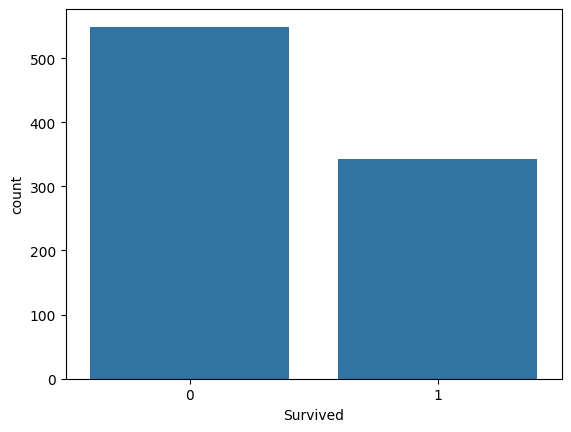

In [6]:
#学習データの目的変数「Survived(生死のフラグ)」を図示
sns.countplot(x='Survived', data=train)

<Axes: xlabel='Pclass', ylabel='count'>

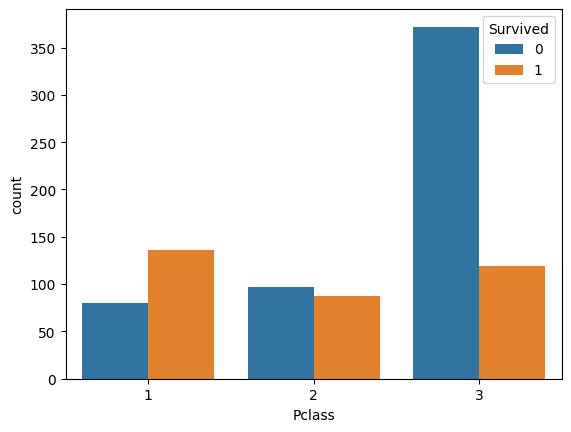

In [7]:
#学習データの「Pclass(チケットのランク)」の確認
sns.countplot(x='Pclass', hue='Survived', data=train)

In [8]:
#学習データの「Name(姓名)」の確認
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
#SurvivedデータとNameデータとを取り出し
Title_tr = train[['Survived', 'Name']]

In [10]:
#Nameデータの2番目の領域(敬称)を抽出
train['Title_tr'] = train['Name'].map(lambda x: x.split(', ')[1].split('. ')[0])

In [11]:
#敬称の一覧を表示
train['Title_tr'].value_counts()

Title_tr
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [12]:
#敬称で少数のものをOthersに分類して、再一覧
train['Title_tr'] = train['Title_tr'].replace(['Dr','Rev','Mlle','Major','Col','the Countess','Capt','Ms','Sir','Lady','Mme','Don','Jonkheer'], 'Others')
train['Title_tr'].value_counts()

Title_tr
Mr        517
Miss      182
Mrs       125
Master     40
Others     27
Name: count, dtype: int64

In [13]:
#敬称ごとの生存率
train['Survived'].groupby(train['Title_tr']).agg(['mean', 'count'])

,mean,count
Title_tr,,
Master,0.575000,40
Miss,0.697802,182
Mr,0.156673,517
Mrs,0.792000,125
Others,0.444444,27


<Axes: xlabel='Sex', ylabel='count'>

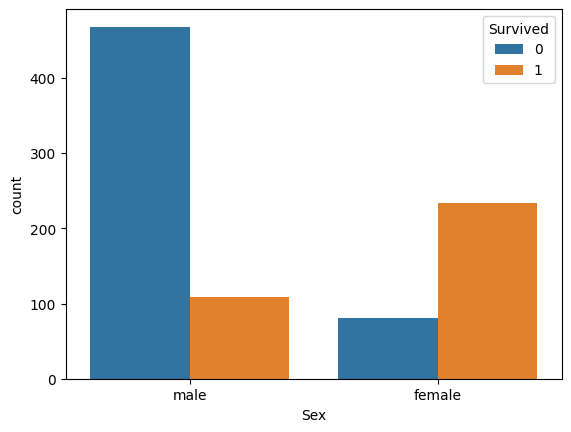

In [14]:
#「Sex(性別)」の確認
sns.countplot(x='Sex', hue='Survived', data=train)

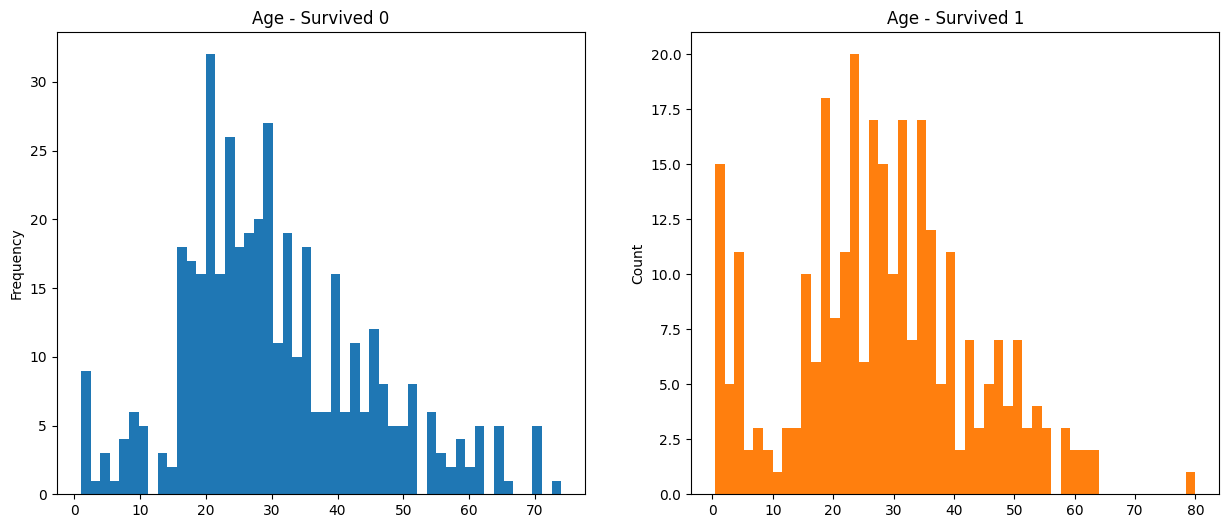

In [15]:
#「Age(年齢)」の確認
cmap = plt.get_cmap('tab10')
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
train[train['Survived']==0]['Age'].plot(kind='hist', bins=50, title='{} - {} 0'.format('Age', 'Survived'), color=cmap(0), ax=ax[0])
train[train['Survived']==1]['Age'].plot(kind='hist', bins=50, title='{} - {} 1'.format('Age', 'Survived'), color=cmap(1), ax=ax[1])
plt.ylabel('Count')
plt.show()

In [16]:
#「Pclass(チケットのランク)」ごとの平均年齢を確認
train.groupby('Pclass').describe()['Age']
#Pclassごとに、平均年齢が異なる

,count,mean,std,min,25%,50%,75%,max
Pclass,,,,,,,,
1,186.0,38.233441,14.802856,0.92,27.0,37.0,49.0,80.0
2,173.0,29.877630,14.001077,0.67,23.0,29.0,36.0,70.0
3,355.0,25.140620,12.495398,0.42,18.0,24.0,32.0,74.0


/tmp/ipykernel_16/4174358966.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='SibSp', y='Survived', data=train, palette='Set1')


<Axes: xlabel='SibSp', ylabel='Survived'>

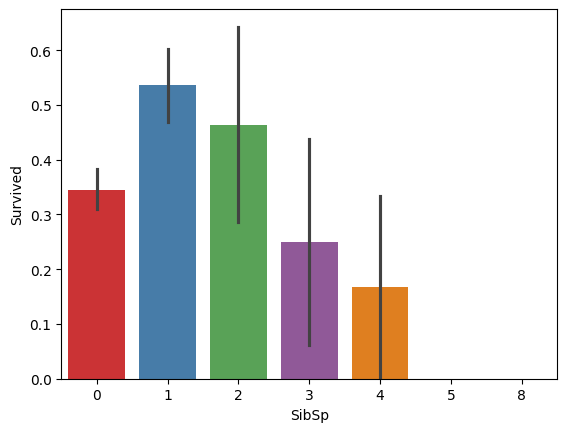

In [17]:
#「SibSp(同乗している兄弟、配偶者の数)」の確認
sns.barplot(x='SibSp', y='Survived', data=train, palette='Set1')
#SibSpが大きいと、生存率が低下する傾向あり

/tmp/ipykernel_16/215355010.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Parch', y='Survived', data=train, palette='Set1')


<Axes: xlabel='Parch', ylabel='Survived'>

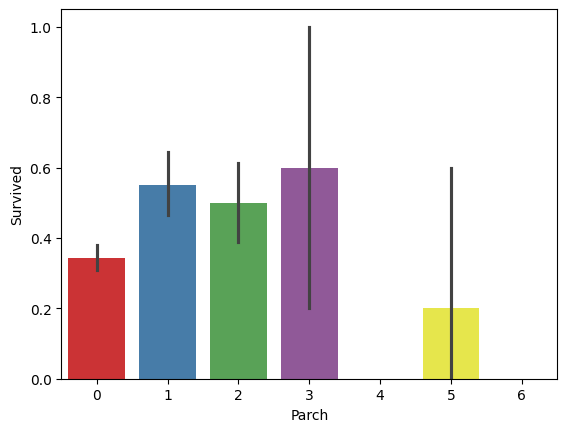

In [18]:
#「Parch(同乗している親、子供の数)」の確認
sns.barplot(x='Parch', y='Survived', data=train, palette='Set1')
#生存率には、ばらつきがある

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(*plot_args, **plot_kwargs)


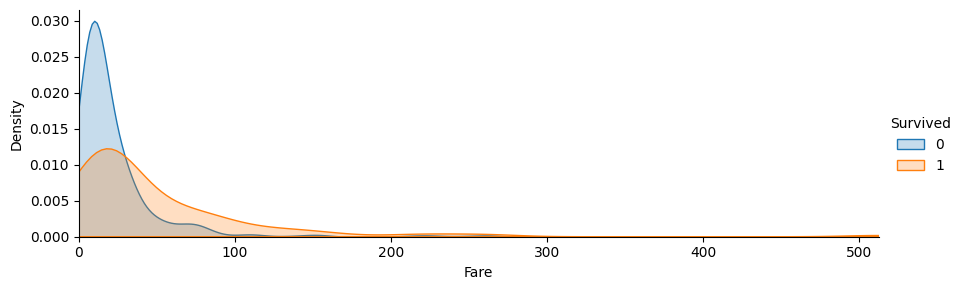

In [19]:
#「Fare(料金)」の確認
fare_s = sns.FacetGrid(train, hue='Survived',aspect=3)
fare_s.map(sns.kdeplot,'Fare',shade= True)
fare_s.set(xlim=(0, train['Fare'].max()))
fare_s.add_legend()
#料金が低いほど、生存率も低い

/tmp/ipykernel_16/3802358134.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Embarked', y='Survived', data=train, palette='Set1')


<Axes: xlabel='Embarked', ylabel='Survived'>

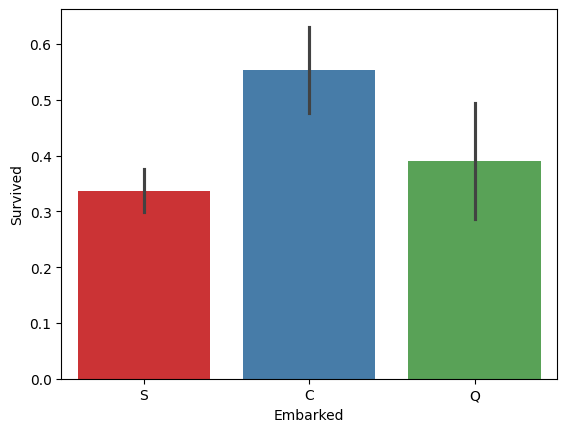

In [20]:
#「Embarked(出港地)」の確認
#S＝ササンプトン、C＝シェルブール、Q＝クイーンズタウン、
sns.barplot(x='Embarked', y='Survived', data=train, palette='Set1')
#出港地により、生存率に差がある

## **各データを可視化してわかったこと**
「Age(年齢)」の件数が、他の特徴量と比べて少ない

生存者より死亡者が多い

チケットのランクが高い程、生存率が高い

「Name(姓名)」中に記載されている敬称(title)から性別と年齢が推定できる。（「Age(年齢)」に欠損値が多いので、敬称を利用することで、年齢に関する情報を補える可能性がある）

女性の方が、生存率が高い

「Pclass(チケットのランク)」ごとに、平均年齢が異なる

「SibSp(同乗している兄弟、配偶者の数)」が大きいと、生存率が低下する傾向がありそう

「Fare(料金)」が低いほど、生存率も低いよう

「Embarked(出港地)」により、生存率に差がある模様

In [21]:
#「Sex(性別)」の前処理　学習データ
train=train.replace({'male': 0 ,'female': 1 })
train.head()

/tmp/ipykernel_16/964820698.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train=train.replace({'male': 0 ,'female': 1 })


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title_tr
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,C,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,S,Mrs
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,S,Mr


In [22]:
#「Sex(性別)」の前処理　テストデータ
test=test.replace({'male': 0 ,'female': 1 })
test.head()

/tmp/ipykernel_16/2572999724.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test=test.replace({'male': 0 ,'female': 1 })


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",0,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",1,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",0,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",0,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",1,22.0,1,1,3101298,12.2875,NaN,S


## 1. 「Name（名前）」と「Embarked（出港地）」を特徴量に追加する理由

前節（3.3節）では、以下の4つの特徴量だけで予測していました。

* `Pclass`（チケットのクラス）
* `Sex`（性別）
* `Age`（年齢）
* `Fare`（運賃）

しかし、データを詳しく観察すると、**名前**や**乗船した港**にも生存率に大きな関わりがあることが分かります。

### 🔹 Name（名前）から「敬称」を取り出す理由

名前には `Mr.`（男性）、`Mrs.`（既婚女性）、`Miss.`（未婚女性）、`Master.`（男の子）といった敬称（Title）が含まれています。

* **得られる情報:** 単なる性別だけでなく、「大人の男性なのか、小さな男の子なのか」「既婚か未婚か」といった年齢や社会的な立場が判断できます。
* **背景:** 「子供や女性が優先的に救命ボートに乗せられた」というタイタニック号の史実があるため、この敬称データ（`Title_tr` / `Title_te`）を追加することで予測精度が高まります。

### 🔹 Embarked（出港地）を追加する理由

乗客が船に乗った港（`C`＝シェルブール、`Q`＝クイーンズタウン、`S`＝サザンプトン）によって、乗客層の裕福さ（1等客が多い港か、3等客が多い港か）に偏りがあることがデータ分析で明らかになりました。


## 2. 「Age（年齢）」の欠損値を「Pclass毎の中央値」で埋める理由

データの中に空欄（欠損値）があると、AI（機械学習モデル）は学習を進めることができません。

* **全体の単純な中央値で埋める場合（3.3節）**
* 乗客全員の年齢の中央値（約28歳）で一律に埋めていました。


* **Pclass（チケットクラス）毎の中央値で埋める理由（3.4節）**
* データを観察すると、「1等客室の乗客は平均年齢が高く（約37歳）、3等客室の乗客は若い（約24歳）」という傾向が見られます。
* 3等客室に乗っている若い乗客の空欄を「全員の真ん中である28歳」で埋めてしまうと、実際の年齢から大きく離れてしまいます。
* そのため、「1等室の欠損値は1等室の中央値」「3等室の欠損値は3等室の中央値」というように、**チケットのランクに合わせたより正確な推定年齢で埋める**ことで、データの精度を上げています。




## 3. 「Embarked（出港地）」をダミー変数化する理由

AI（機械学習モデル）は「文字（`C`, `Q`, `S`）」のままでは計算ができないため、数字に変換する必要があります。

### ❓ なぜ単に `C=1, Q=2, S=3` と番号を振るのがダメなのか？

文字を単純に `1, 2, 3` という数値にしてしまうと、AI が「`S(3)` は `C(1)` の3倍大きい」「`Q(2)` は `C(1)` と `S(3)` の平均だ」というような、**存在しない上下関係や数値としての大小意味を勝手に学習してしまう**からです。

### 💡 ダミー変数化（`pd.get_dummies`）の仕組み

`Embarked` 列を、「C港か？(0か1)」「Q港か？(0か1)」「S港か？(0か1)」という独立した3つの列に分解します。

| 乗客 | 元のEmbarked | C | Q | S |
| --- | --- | --- | --- | --- |
| 乗客A | **S** | 0 | 0 | **1** |
| 乗客B | **C** | **1** | 0 | 0 |
| 乗客C | **Q** | 0 | **1** | 0 |

このように「はい（1）か いいえ（0）」だけの列に変換する処理を**ダミー変数化**と呼びます。これにより、数値の大小関係に誤解を与えずに、AI に正しく場所の情報を伝えることができます。



In [23]:
#①名前から「敬称」だけを取り出す　学習データ

train['Title_tr'] = train['Name'].map(lambda x: x.split(', ')[1].split('. ')[0])

In [24]:
#②取り出した敬称の一覧と件数を表示　学習データ
train['Title_tr'].value_counts()

Title_tr
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [25]:
#③人数が少ない珍しい敬称を「Others」にまとめる　学習データ
train['Title_tr'] = train['Title_tr'].replace(['Dr','Rev','Mlle','Major','Col','the Countess','Capt','Ms','Sir','Lady','Mme','Don','Jonkheer'], 'Others')
train['Title_tr'].value_counts()

Title_tr
Mr        517
Miss      182
Mrs       125
Master     40
Others     27
Name: count, dtype: int64

In [26]:
#④敬称（文字列）を数字に置き換える　学習データ
train['Title_tr'] = train['Title_tr'].map( {'Master': 0 , 'Miss':1 , 'Mr':2, 'Mrs':3, 'Others':4})
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title_tr
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,S,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,C,3
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,S,3
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,S,2


In [27]:
#①名前から「敬称」だけを取り出す　　テストデータ
test['Title_te'] = test['Name'].map(lambda x: x.split(', ')[1].split('. ')[0])

In [28]:
#②取り出した敬称の一覧と件数を表示　 テストデータ
test['Title_te'].value_counts()

Title_te
Mr        240
Miss       78
Mrs        72
Master     21
Col         2
Rev         2
Ms          1
Dr          1
Dona        1
Name: count, dtype: int64

In [29]:
#③人数が少ない珍しい敬称を「Others」にまとめる　テストデータ
test['Title_te'] = test['Title_te'].replace(['Col','Rev','Ms','Dr','Dona'], 'Others')
test['Title_te'].value_counts()

Title_te
Mr        240
Miss       78
Mrs        72
Master     21
Others      7
Name: count, dtype: int64

In [30]:
#④敬称（文字列）を数字に置き換える　　テストデータ
test['Title_te'] = test['Title_te'].map( {'Master': 0 , 'Miss':1 , 'Mr':2, 'Mrs':3, 'Others':4})
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title_te
0,892,3,"Kelly, Mr. James",0,34.5,0,0,330911,7.8292,NaN,Q,2
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",1,47.0,1,0,363272,7.0000,NaN,S,3
2,894,2,"Myles, Mr. Thomas Francis",0,62.0,0,0,240276,9.6875,NaN,Q,2
3,895,3,"Wirz, Mr. Albert",0,27.0,0,0,315154,8.6625,NaN,S,2
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",1,22.0,1,1,3101298,12.2875,NaN,S,3


In [31]:
#「Age(年齢)」の前処理
#Pclass毎に、中央値で穴埋め
train.loc[train['Age'].isnull(), 'Age'] = train.groupby('Pclass')['Age'].transform('median')
test.loc[test['Age'].isnull(), 'Age'] = test.groupby('Pclass')['Age'].transform('median')

In [32]:
#欠損値（空欄）の穴埋め処理 

#テストデータの Fare（運賃）の欠損値1件を「中央値」で穴埋め
#数値データなので、外れ値の影響を受けにくい中央値（median()）
test['Fare'] = test['Fare'].fillna(test['Fare'].median())

In [33]:
#欠損値（空欄）の穴埋め処理

#学習データの Embarked（乗船港）の欠損値2件を「最頻値（一番多かった港）」で穴埋め
#文字データ（C, Q, S）なので、最も人数の多かった港である最頻値（mode()[0]）
train['Embarked'] = train['Embarked'].fillna(train['Embarked'].mode()[0])

In [34]:
#欠損値（空欄）が消えたかの最終チェック
train.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
Title_tr         0
dtype: int64

In [35]:
#欠損値（空欄）が消えたかの最終チェック
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
Title_te         0
dtype: int64

In [36]:
#ダミー変数化
#pd.get_dummies(...)  Pandasが用意しているダミー変数化を行う関数
#train['Embarked'] 変換の対象とする列（データ）を指定
#作成する 0 や 1 のデータ型（データの保持形式）を「符号なし8ビット整数」に指定

train_embarked_dum = pd.get_dummies(train['Embarked'], dtype='uint8')

In [37]:
#作成したダミー変数のデータフレームを、元の学習データ（train）の右側に横方向で結合
#axis=1（横方向）: 元のデータの右側に、新しい列（C, Q, S）を追加
#train_add_dum という新しい変数に代入して保存

train_add_dum = pd.concat([train,train_embarked_dum], axis=1 )
train_add_dum.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title_tr,C,Q,S
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,S,2,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,C,3,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,S,3,0,0,1
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,S,2,0,0,1


In [38]:
#テストデータについても、同様の対応を実施
test_embarked_dum = pd.get_dummies(test['Embarked'], dtype='uint8')
test_add_dum = pd.concat([test,test_embarked_dum], axis=1 )
test_add_dum.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title_te,C,Q,S
0,892,3,"Kelly, Mr. James",0,34.5,0,0,330911,7.8292,NaN,Q,2,0,1,0
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",1,47.0,1,0,363272,7.0000,NaN,S,3,0,0,1
2,894,2,"Myles, Mr. Thomas Francis",0,62.0,0,0,240276,9.6875,NaN,Q,2,0,1,0
3,895,3,"Wirz, Mr. Albert",0,27.0,0,0,315154,8.6625,NaN,S,2,0,0,1
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",1,22.0,1,1,3101298,12.2875,NaN,S,3,0,0,1


## 予測モデルの作成と予測の実施

**特徴量**：「Pclass(チケットのランク)」「Name(名称)」「Sex(性別)」「Age(年齢)」「Fare(料金)」「Embarked(出港地)」

**目的変数**：「Survived（生死のフラグ）」


## 決定木による分析 #1で実施した分析との比較

**１「Age」の欠損値処理の精度向上**
チケットクラス）毎の中央値

**２「Name」、「Embarked(出港地)」を追加**
「Name」　敬称を抽出／グループ化の上、数値化
「Embarked」ダミー変数化の上で、「C」「Q」「S」を追加


In [39]:
#「決定木モデル」の利用のために、scikit-learnライブラリのtreeモジュールをインポート
from sklearn import tree


#データフレーム train_add_dum から、AIに学習させたい8つの列を選択
#.values データフレーム（Pandasの表形式）から、「数値だけの2次元配列（NumPy Array）」に変換
#変換したデータを train_features変数に保存

train_features = train_add_dum[['Pclass', 'Sex', 'Age', 'Fare', 'Title_tr', 'C', 'Q', 'S']].values
train_target = train['Survived'].values

In [40]:
#学習を実施
model = tree.DecisionTreeClassifier(max_depth = 5, class_weight = 'balanced', random_state=0)
model.fit(train_features, train_target)


DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=0)

In [41]:
#テストデータも同様に特徴量を取得
test_features = test_add_dum[['Pclass', 'Sex', 'Age', 'Fare','Title_te', 'C', 'Q', 'S']].values

In [42]:
#作成したモデルで目的変数を予測
predict_test_target = model.predict(test_features)

In [43]:
#predict_test_target.shape
predict_test_target.shape

(418,)

In [44]:
print(predict_test_target)

[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 0 1 1 0 1 0 1 0 0 0 0 0 1 0 0 0 1
 1 0 0 0 1 0 1 1 0 0 0 1 1 0 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 1 1 0 1 0
 1 0 0 1 0 1 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 0 0
 1 0 1 0 0 1 0 0 1 1 1 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 1 0 1 0 1 1 0 1 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0
 1 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 1 0 0
 1 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 1 0
 0 1 0 0 1 1 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0
 0 1 1 1 1 1 0 1 0 0 0]


In [45]:
#予測データの提出
submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': predict_test_target})
submission.to_csv('submission_Titanic_DecisionTreeClassifier_2.csv', index = False )